# Day 13: Secondary Malolactic Fermentation, Precision Oak Barrel Maturation, Digital Cellar Dispatch & HACCP Auditor
**Project:** Wine Quality Prediction (UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Milestone:** Day 13 Enterprise Enology Platform Expansion

### Key Architectural Capabilities:
1. **Secondary Malolactic Fermentation (MLF) Biotransformation:** Decarboxylation of dicarboxylic L-malic acid into monocarboxylic L-lactic acid and CO2 by *Oenococcus oeni*, tracking pH elevation, fixed acidity drop, and diacetyl buttery synthesis.
2. **Precision Oak Barrel Maturation Dynamics:** First-order Fickian dissolution kinetics of wood ellagitannins, oak lactones, vanillin, and guaiacol smoke across French, American, and Hungarian oak, with micro-oxygenation polymeric pigment color stabilization.
3. **Digital Cellar Master Work-Order Dispatch Engine:** Multi-vessel risk triage calculating the Enological Risk Priority Index (ERPI) and generating prescriptive chemical additions (Potassium Metabisulfite PMS doses, lysozyme, topping).
4. **HACCP Food Safety & Biogenic Amine Risk Auditor:** Statutory verification of Critical Control Points (CCPs), molecular SO2 antimicrobial envelopes, and biogenic amine (histamine/tyramine) hazard scoring.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('.').resolve()))

import json
import pandas as pd
import numpy as np
from src.malolactic_and_oak import (
    MalolacticFermentationSimulator,
    OakBarrelMaturationSimulator,
    CellarMasterDispatchEngine,
    EnologicalHaccpAuditor
)
from src.production_service import get_test_client
print('Day 13 modules imported successfully!')

Day 13 modules imported successfully!


## 1. Secondary Malolactic Fermentation (MLF) Simulation

We simulate *Oenococcus oeni* bioconversion of L-malic acid under optimal conditions (20°C, 5 mg/L Free SO2) and compare against cold cellar (13°C) and high-sulfur (16 mg/L Free SO2) inhibition conditions.

In [2]:
sim = MalolacticFermentationSimulator()
res_opt = sim.simulate(initial_malic_acid=2.8, initial_ph=3.35, alcohol=13.0, free_so2=5.0, temperature=20.0, duration_days=35)
res_cold = sim.simulate(initial_malic_acid=2.8, initial_ph=3.35, alcohol=13.0, free_so2=5.0, temperature=13.0, duration_days=35)
res_so2 = sim.simulate(initial_malic_acid=2.8, initial_ph=3.35, alcohol=13.0, free_so2=16.0, temperature=20.0, duration_days=35)

print('=== Optimal MLF (20°C, 5 mg/L Free SO2) ===')
print('Final Malic Acid (g/L):', res_opt['final_state']['malic_acid_g_l'])
print('Final Lactic Acid (g/L):', res_opt['final_state']['lactic_acid_g_l'])
print('Final pH:', res_opt['final_state']['ph'])
print('Fixed Acidity (g/L):', res_opt['final_state']['fixed_acidity_g_l'])
print('Peak Diacetyl (mg/L):', res_opt['final_state']['peak_diacetyl_mg_l'])
print('MLF Complete:', res_opt['diagnostics']['is_complete'])
print('Sensory Description:', res_opt['diagnostics']['sensory_descriptor'])

print('\n=== Environmental Stress Comparison ===')
print('Cold Cellar Conversion (%):', res_cold['final_state']['conversion_rate_pct'])
print('High SO2 Conversion (%):', res_so2['final_state']['conversion_rate_pct'])

=== Optimal MLF (20°C, 5 mg/L Free SO2) ===
Final Malic Acid (g/L): 0.0043
Final Lactic Acid (g/L): 1.8781
Final pH: 3.532
Fixed Acidity (g/L): 5.579
Peak Diacetyl (mg/L): 0.419
MLF Complete: True
Sensory Description: Complete MLF: Velvety mouthfeel, rounded deacidification, integrated lactic richness.

=== Environmental Stress Comparison ===
Cold Cellar Conversion (%): 82.63
High SO2 Conversion (%): 85.46


## 2. Precision Oak Barrel Maturation & Wood Phenolics Extraction

Dynamic wood extractives simulation across French (*Quercus petraea*), American (*Quercus alba*), and Hungarian (*Quercus frainetto*) oak species, tracking ellagitannins, oak lactones, vanillin, and polymeric pigment color stabilization.

In [3]:
oak_sim = OakBarrelMaturationSimulator()
res_french = oak_sim.simulate(oak_species='french', toast_level='medium_plus', barrel_usage='new', maturation_months=24)
res_american = oak_sim.simulate(oak_species='american', toast_level='medium', barrel_usage='new', maturation_months=24)
res_neutral = oak_sim.simulate(oak_species='french', toast_level='medium', barrel_usage='neutral', maturation_months=24)

df_oak = pd.DataFrame([
    {
        'Profile': 'French New (Med+)',
        'Ellagitannins (mg/L)': res_french['final_concentrations']['ellagitannins_mg_l'],
        'Lactones (mg/L)': res_french['final_concentrations']['whiskey_lactones_mg_l'],
        'Vanillin (mg/L)': res_french['final_concentrations']['vanillin_mg_l'],
        'Guaiacol Smoke (mg/L)': res_french['final_concentrations']['guaiacol_mg_l'],
        'Polymer Pigment': res_french['final_concentrations']['polymeric_pigment_index'],
        'Oak Intensity (0-100)': res_french['final_concentrations']['oak_intensity_score'],
    },
    {
        'Profile': 'American New (Med)',
        'Ellagitannins (mg/L)': res_american['final_concentrations']['ellagitannins_mg_l'],
        'Lactones (mg/L)': res_american['final_concentrations']['whiskey_lactones_mg_l'],
        'Vanillin (mg/L)': res_american['final_concentrations']['vanillin_mg_l'],
        'Guaiacol Smoke (mg/L)': res_american['final_concentrations']['guaiacol_mg_l'],
        'Polymer Pigment': res_american['final_concentrations']['polymeric_pigment_index'],
        'Oak Intensity (0-100)': res_american['final_concentrations']['oak_intensity_score'],
    },
    {
        'Profile': 'French Neutral (4th Fill)',
        'Ellagitannins (mg/L)': res_neutral['final_concentrations']['ellagitannins_mg_l'],
        'Lactones (mg/L)': res_neutral['final_concentrations']['whiskey_lactones_mg_l'],
        'Vanillin (mg/L)': res_neutral['final_concentrations']['vanillin_mg_l'],
        'Guaiacol Smoke (mg/L)': res_neutral['final_concentrations']['guaiacol_mg_l'],
        'Polymer Pigment': res_neutral['final_concentrations']['polymeric_pigment_index'],
        'Oak Intensity (0-100)': res_neutral['final_concentrations']['oak_intensity_score'],
    }
])
display(df_oak)

,Profile,Ellagitannins (mg/L),Lactones (mg/L),Vanillin (mg/L),Guaiacol Smoke (mg/L),Polymer Pigment,Oak Intensity (0-100)
0,French New (Med+),187.87,1.712,4.227,1.174,52.15,73.5
1,American New (Med),109.44,5.034,6.925,1.075,52.15,100.0
2,French Neutral (4th Fill),18.79,0.121,0.301,0.056,52.15,4.7


## 3. Digital Cellar Master Dispatch Engine

Simulates multi-vessel fleet triage across winery cellar vessels, computing the Enological Risk Priority Index (ERPI) and generating prescriptive chemical additions (Potassium Metabisulfite PMS).

In [4]:
dispatch = CellarMasterDispatchEngine()
fleet = [
    {'vessel_id': 'BARREL-FR-01', 'vessel_type': 'BARREL', 'cultivar': 'red', 'volume_liters': 225.0, 'ph': 3.42, 'free_so2': 14.0, 'total_so2': 65.0, 'volatile_acidity': 0.42, 'alcohol': 13.5, 'temperature': 17.5, 'residual_sugar': 1.8, 'malic_acid': 0.04, 'maturation_days': 120, 'status': 'aging'},
    {'vessel_id': 'TANK-FERM-03', 'vessel_type': 'TANK', 'cultivar': 'red', 'volume_liters': 5000.0, 'ph': 3.65, 'free_so2': 8.0, 'total_so2': 45.0, 'volatile_acidity': 0.78, 'alcohol': 12.8, 'temperature': 23.5, 'residual_sugar': 6.5, 'malic_acid': 0.85, 'maturation_days': 21, 'status': 'aging'},
    {'vessel_id': 'BARREL-US-08', 'vessel_type': 'BARREL', 'cultivar': 'red', 'volume_liters': 225.0, 'ph': 3.50, 'free_so2': 11.0, 'total_so2': 55.0, 'volatile_acidity': 0.52, 'alcohol': 13.8, 'temperature': 18.0, 'residual_sugar': 1.9, 'malic_acid': 0.05, 'maturation_days': 210, 'status': 'aging'},
    {'vessel_id': 'TANK-WHITE-02', 'vessel_type': 'TANK', 'cultivar': 'white', 'volume_liters': 10000.0, 'ph': 3.20, 'free_so2': 28.0, 'total_so2': 110.0, 'volatile_acidity': 0.32, 'alcohol': 12.2, 'temperature': 13.0, 'residual_sugar': 4.5, 'malic_acid': 1.80, 'maturation_days': 60, 'status': 'resting'},
    {'vessel_id': 'BARREL-VINTAGE-99', 'vessel_type': 'BARREL', 'cultivar': 'red', 'volume_liters': 225.0, 'ph': 3.82, 'free_so2': 6.0, 'total_so2': 90.0, 'volatile_acidity': 1.05, 'alcohol': 14.2, 'temperature': 21.0, 'residual_sugar': 2.0, 'malic_acid': 0.45, 'maturation_days': 340, 'status': 'aging'}
]
dispatch_summary = dispatch.dispatch_cellar_inventory(fleet)
print('=== Cellar Master Fleet Triage Summary ===')
print('Total Vessels Evaluated:', dispatch_summary['total_vessels'])
print('Tier Distribution:', dispatch_summary['tier_distribution'])
print('Cellar Health Score (0-100):', dispatch_summary['cellar_health_score'])
print('Aggregate PMS Reagents Required (kg):', dispatch_summary['aggregate_pms_reagents_required_kg'])

# Print Top Urgent Vessel Work Order
top_vessel = dispatch_summary['dispatched_vessels'][0]
print(f'\nTop Priority Vessel: {top_vessel["vessel_id"]} (ERPI: {top_vessel["metrics"]["erpi_score"]})')
print('Action Tier:', top_vessel['triage']['action_tier'])
for idx, wo in enumerate(top_vessel['work_orders'], 1):
    print(f'  Work Order {idx}: {wo["action"]} | Reagent: {wo["chemical"]} | Dose: {wo["dosage_grams"]} g')
    print(f'    Rationale: {wo["rationale"]}')

=== Cellar Master Fleet Triage Summary ===
Total Vessels Evaluated: 5
Tier Distribution: {'CRITICAL_INTERVENTION': 3, 'ACTIVE_MANAGEMENT': 1, 'ROUTINE_MONITORING': 0, 'STABLE_CELLAR': 1}
Cellar Health Score (0-100): 51.7
Aggregate PMS Reagents Required (kg): 0.398

Top Priority Vessel: TANK-FERM-03 (ERPI: 80.2)
Action Tier: CRITICAL_INTERVENTION
  Work Order 1: ADD_SULPHUR_DIOXIDE | Reagent: Potassium Metabisulfite (K2S2O5, 57.6% active SO2) | Dose: 361.8 g
    Rationale: Current Free SO2 (8.0 mg/L) yields deficient molecular SO2 (0.11 mg/L vs target 0.5 mg/L).
  Work Order 2: VOLATILE_ACIDITY_TRIAGE | Reagent: Cellar Temperature Reduction & Inert Gas Blanketing | Dose: 0.0 g
    Rationale: Elevated VA (0.78 g/L) approaching critical threshold. Reduce cellar to 14°C and sparge headspace with Argon/N2.
  Work Order 3: MLF_ARREST_OR_COMPLETION | Reagent: Lysozyme (250 mg/L) or SO2 Fortification | Dose: 1250.0 g
    Rationale: Unfinished malic acid (0.85 g/L) in aging lot risks spontaneou

## 4. HACCP Food Safety & Biogenic Amine Risk Auditor

Performs statutory Critical Control Point (CCP) audits and calculates biogenic amine (histamine, tyramine) decarboxylation hazard scores for production lots.

In [5]:
auditor = EnologicalHaccpAuditor()
audit_pass = auditor.audit_wine_lot(
    lot_id='LOT-RESERVE-2026',
    cultivar='red',
    ph=3.42,
    free_so2=24.0,
    total_so2=85.0,
    volatile_acidity=0.45,
    alcohol=13.5,
    malic_acid=0.03,
    temperature=16.0
)

audit_hazard = auditor.audit_wine_lot(
    lot_id='LOT-STRESSED-02',
    cultivar='red',
    ph=3.85,
    free_so2=5.0,
    total_so2=40.0,
    volatile_acidity=0.65,
    alcohol=12.2,
    malic_acid=0.75,
    temperature=22.0
)

print('=== Safe Lot Audit ===')
print('Status:', audit_pass['audit_status'])
print('All CCPs Passed:', audit_pass['all_ccp_passed'])
print('Biogenic Amine Risk:', audit_pass['biogenic_amine_risk']['risk_level'])
print('Predicted Histamine:', audit_pass['biogenic_amine_risk']['predicted_histamine_content'])

print('=== Stressed Lot Audit ===')
print('Status:', audit_hazard['audit_status'])
print('All CCPs Passed:', audit_hazard['all_ccp_passed'])
print('Biogenic Amine Risk:', audit_hazard['biogenic_amine_risk']['risk_level'], f'({audit_hazard["biogenic_amine_risk"]["risk_index_score"]})')
print('Predicted Histamine:', audit_hazard['biogenic_amine_risk']['predicted_histamine_content'])
print('Findings:', audit_hazard['audit_findings'])

=== Safe Lot Audit ===
Status: CERTIFIED_FOOD_GRADE
All CCPs Passed: True
Biogenic Amine Risk: LOW
Predicted Histamine: < 1.5 mg/L (Safe / Negligible)
=== Stressed Lot Audit ===
Status: NON_COMPLIANT_HOLD
All CCPs Passed: False
Biogenic Amine Risk: MODERATE (53.6)
Predicted Histamine: 2.0 - 6.0 mg/L (Minor Allergen Risk)
Findings: ['CCP-1 FAIL: Molecular SO2 (0.045 mg/L) below sanitary minimum (0.5 mg/L). Wine vulnerable to Brettanomyces.']


## 5. Production REST API Endpoints Verification

We test all four Day 13 REST microservice endpoints using the in-memory FastAPI `TestClient`.

In [6]:
client = get_test_client()

# 1. POST /cellar/malolactic/simulate
r1 = client.post('/cellar/malolactic/simulate', json={
    'initial_malic_acid': 2.8,
    'initial_ph': 3.35,
    'alcohol': 13.0,
    'free_so2': 6.0,
    'temperature': 20.0,
    'duration_days': 35
})
assert r1.status_code == 200
print('POST /cellar/malolactic/simulate: 200 OK | Final Conversion =', r1.json()['final_state']['conversion_rate_pct'], '%')

# 2. POST /cellar/oak-maturation/simulate
r2 = client.post('/cellar/oak-maturation/simulate', json={
    'oak_species': 'french',
    'toast_level': 'medium_plus',
    'barrel_usage': 'new',
    'maturation_months': 18
})
assert r2.status_code == 200
print('POST /cellar/oak-maturation/simulate: 200 OK | Ellagitannins =', r2.json()['final_concentrations']['ellagitannins_mg_l'], 'mg/L')

# 3. POST /cellar/dispatch/work-orders
r3 = client.post('/cellar/dispatch/work-orders', json={'inventory': fleet})
assert r3.status_code == 200
print('POST /cellar/dispatch/work-orders: 200 OK | Total Vessels =', r3.json()['total_vessels'])

# 4. POST /compliance/haccp-audit
r4 = client.post('/compliance/haccp-audit', json={
    'lot_id': 'LOT-TEST-REST',
    'cultivar': 'red',
    'ph': 3.4,
    'free_so2': 22.0,
    'total_so2': 85.0,
    'volatile_acidity': 0.45,
    'alcohol': 13.5
})
assert r4.status_code == 200
print('POST /compliance/haccp-audit: 200 OK | Status =', r4.json()['audit_status'])

POST /cellar/malolactic/simulate: 200 OK | Final Conversion = 99.66 %
POST /cellar/oak-maturation/simulate: 200 OK | Ellagitannins = 181.22 mg/L
POST /cellar/dispatch/work-orders: 200 OK | Total Vessels = 5
POST /compliance/haccp-audit: 200 OK | Status = CERTIFIED_FOOD_GRADE


C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\src\production_service.py:1866: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient


## 6. Publication Figures Gallery

Display the four generated diagnostic figures published in `reports/figures/`.

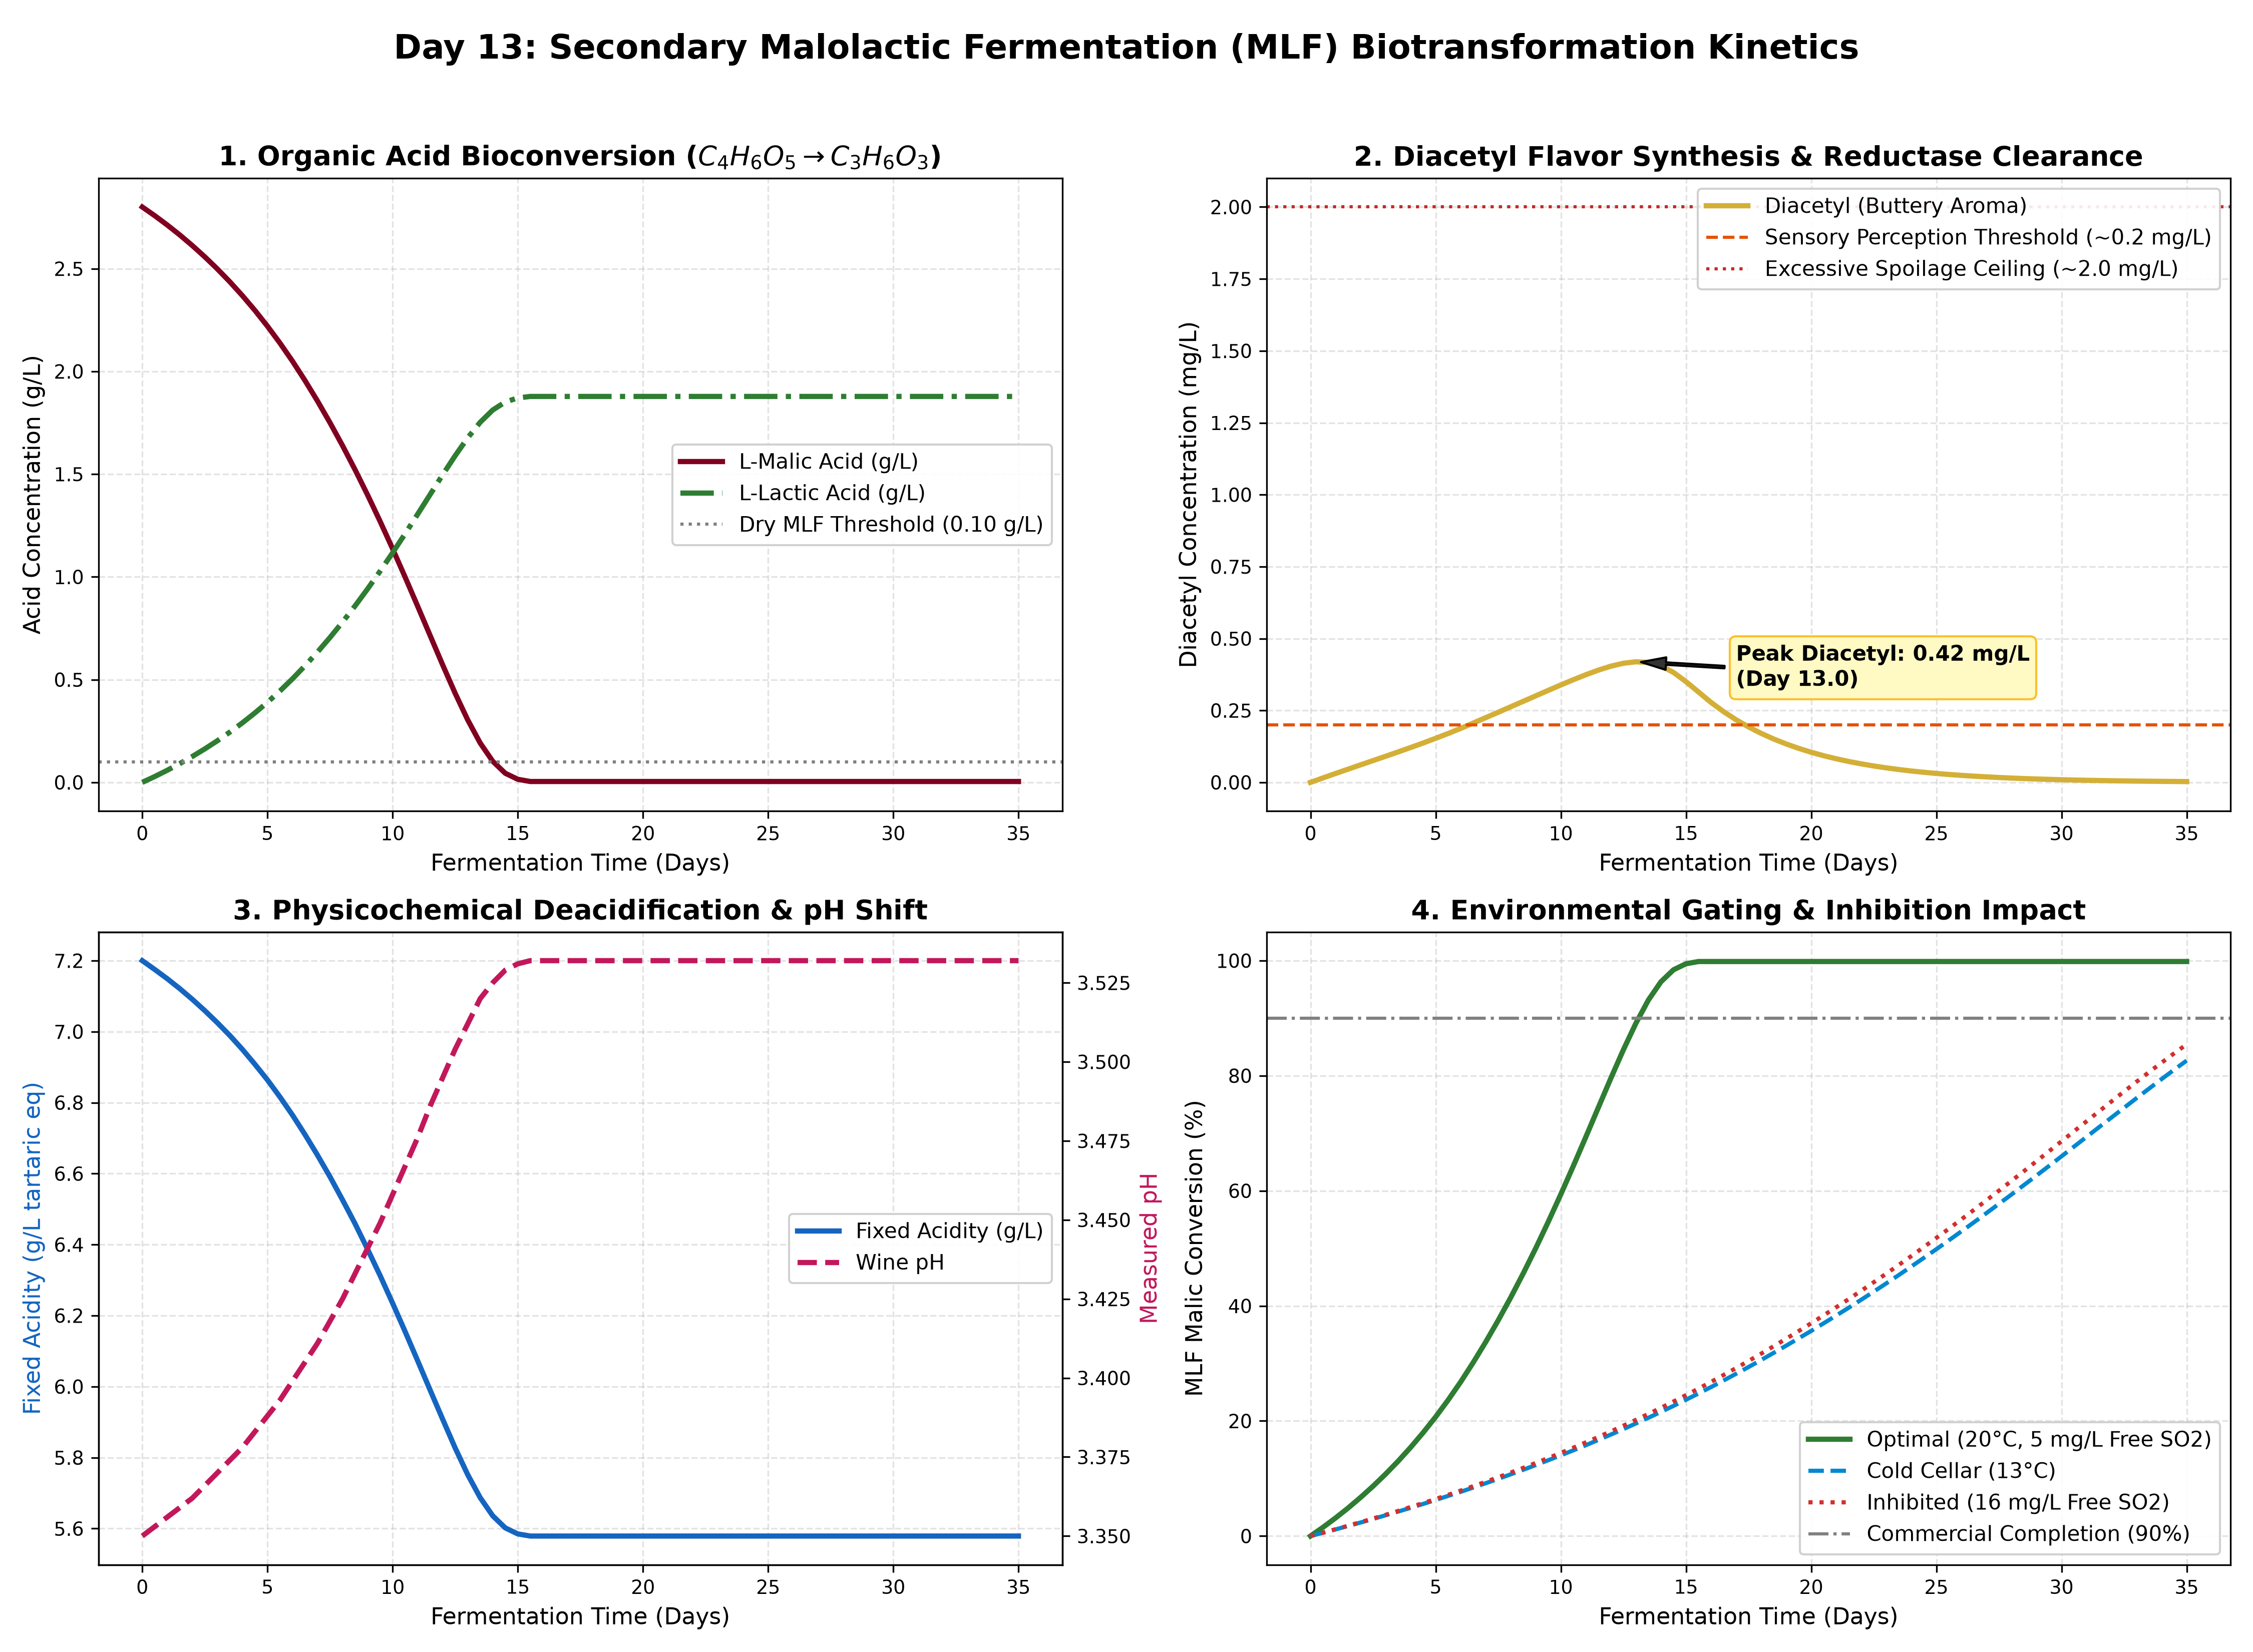

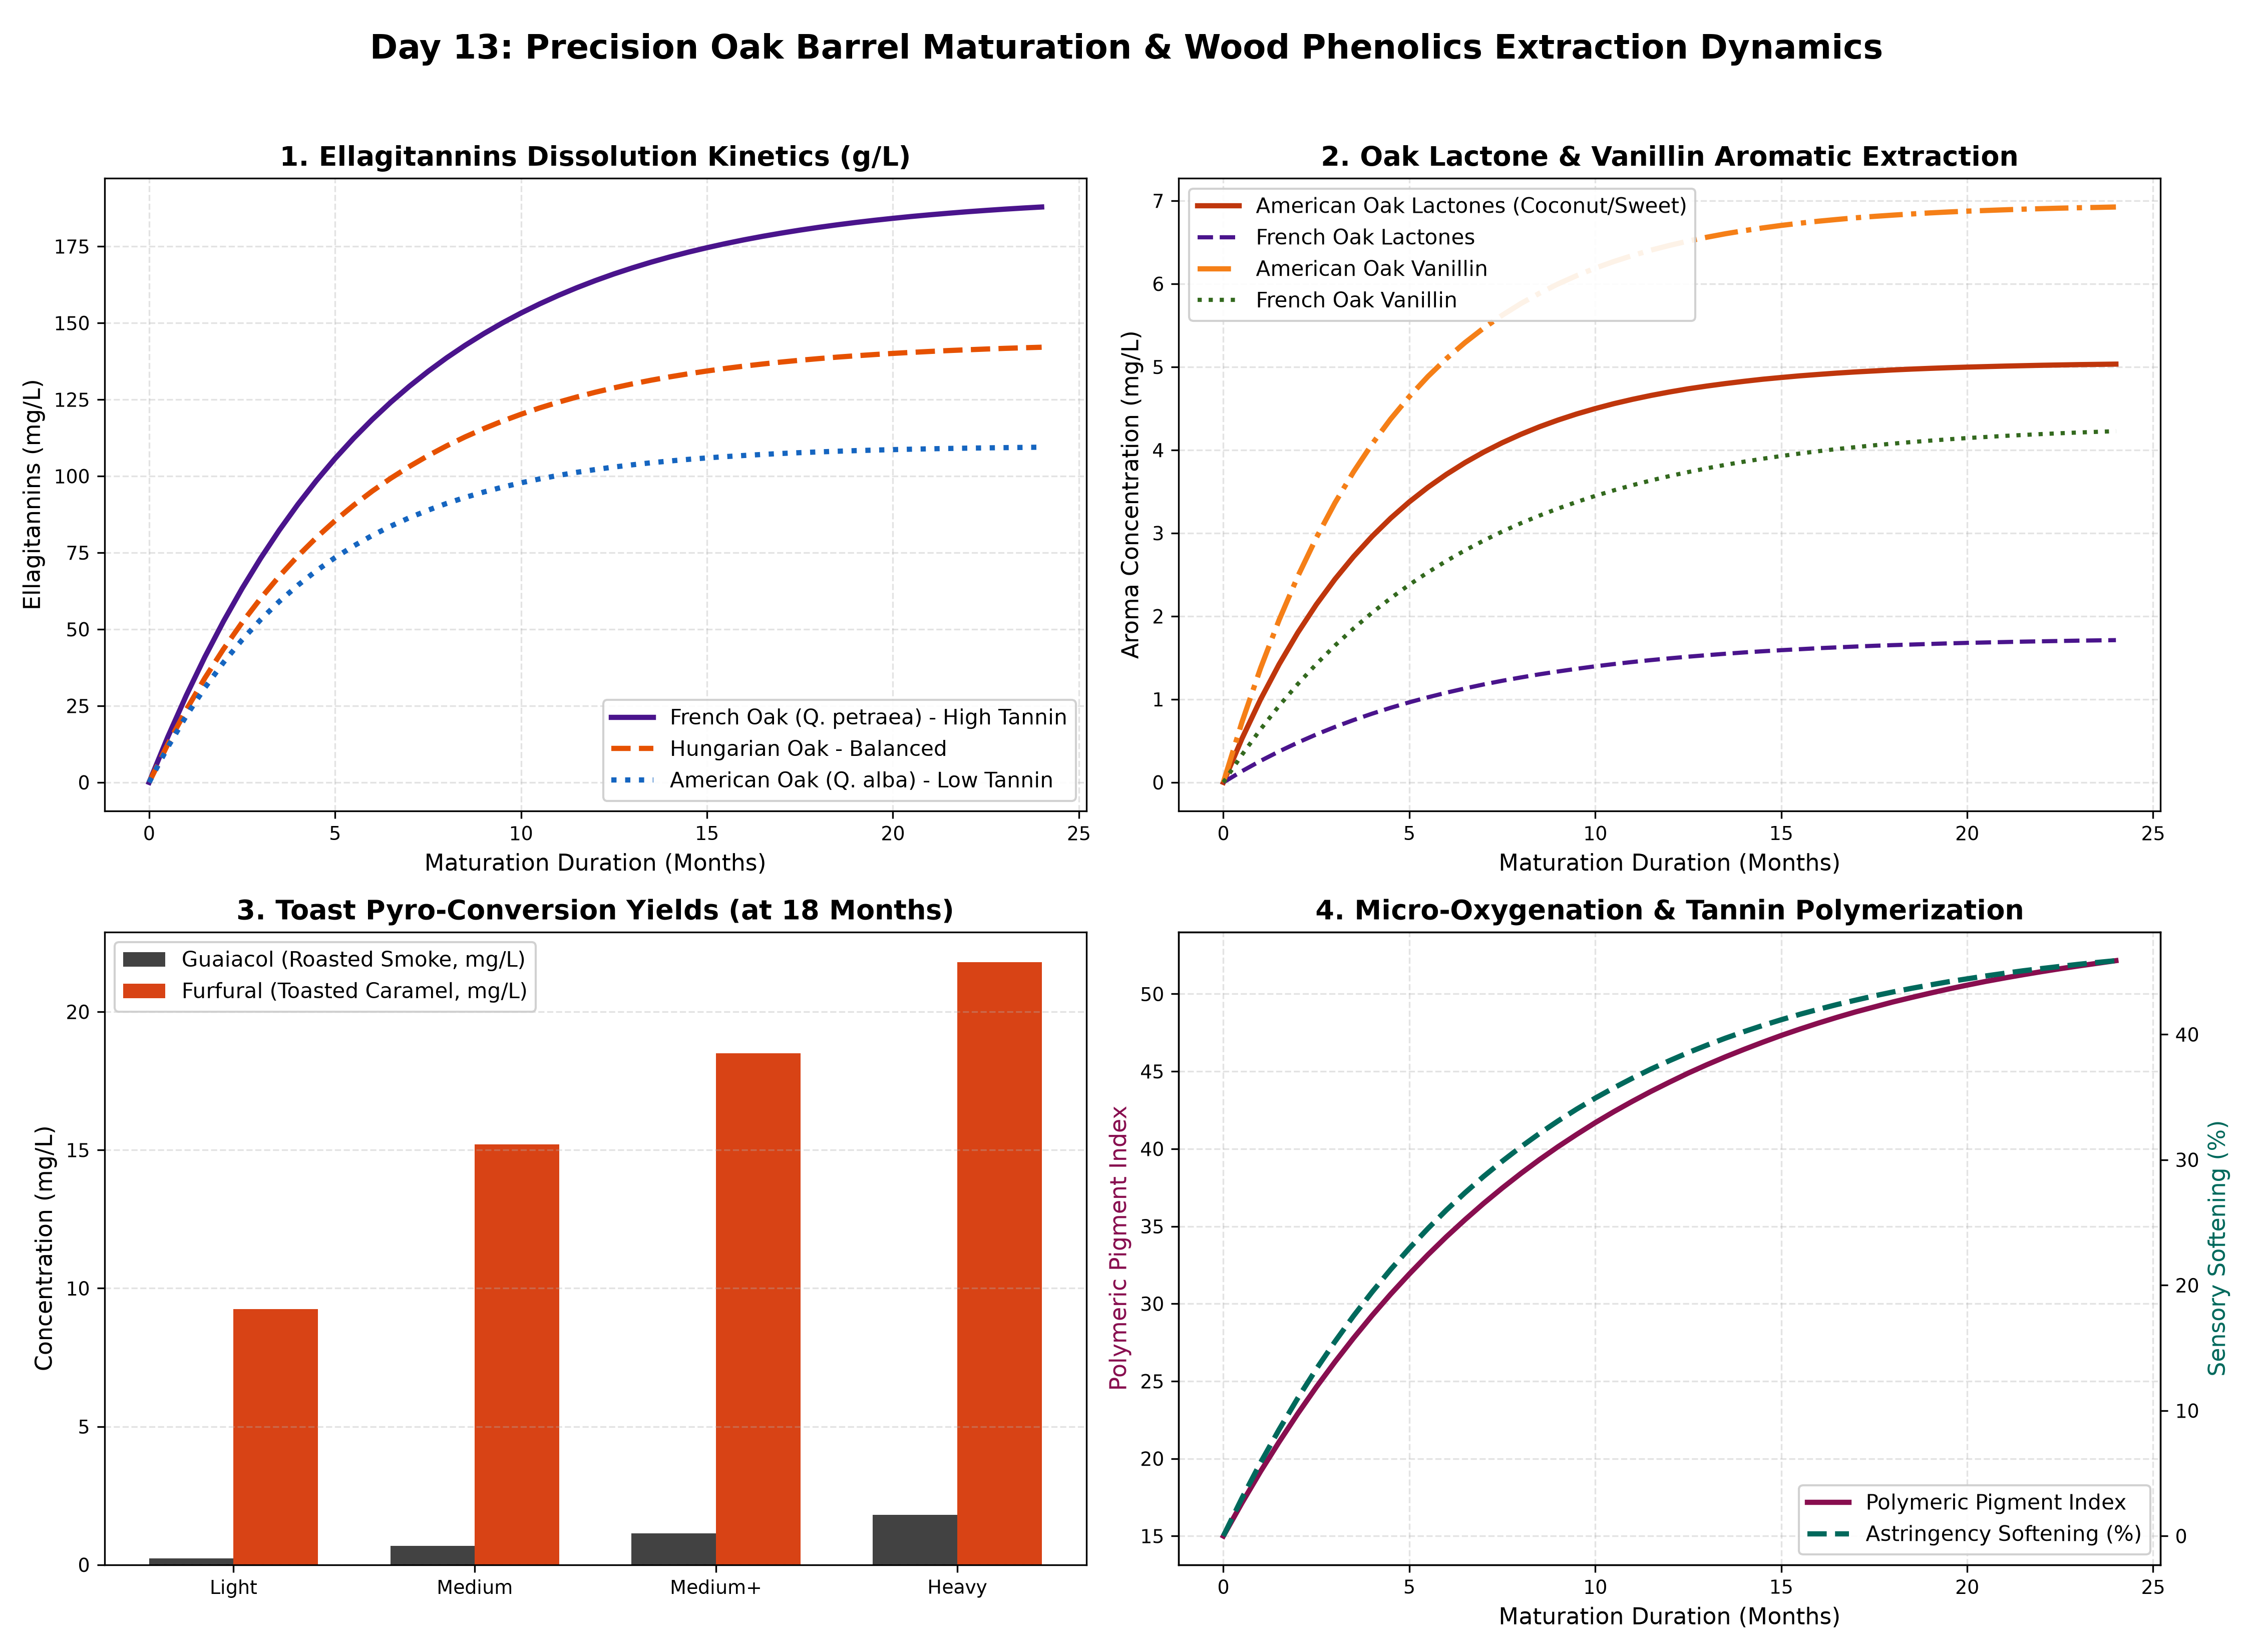

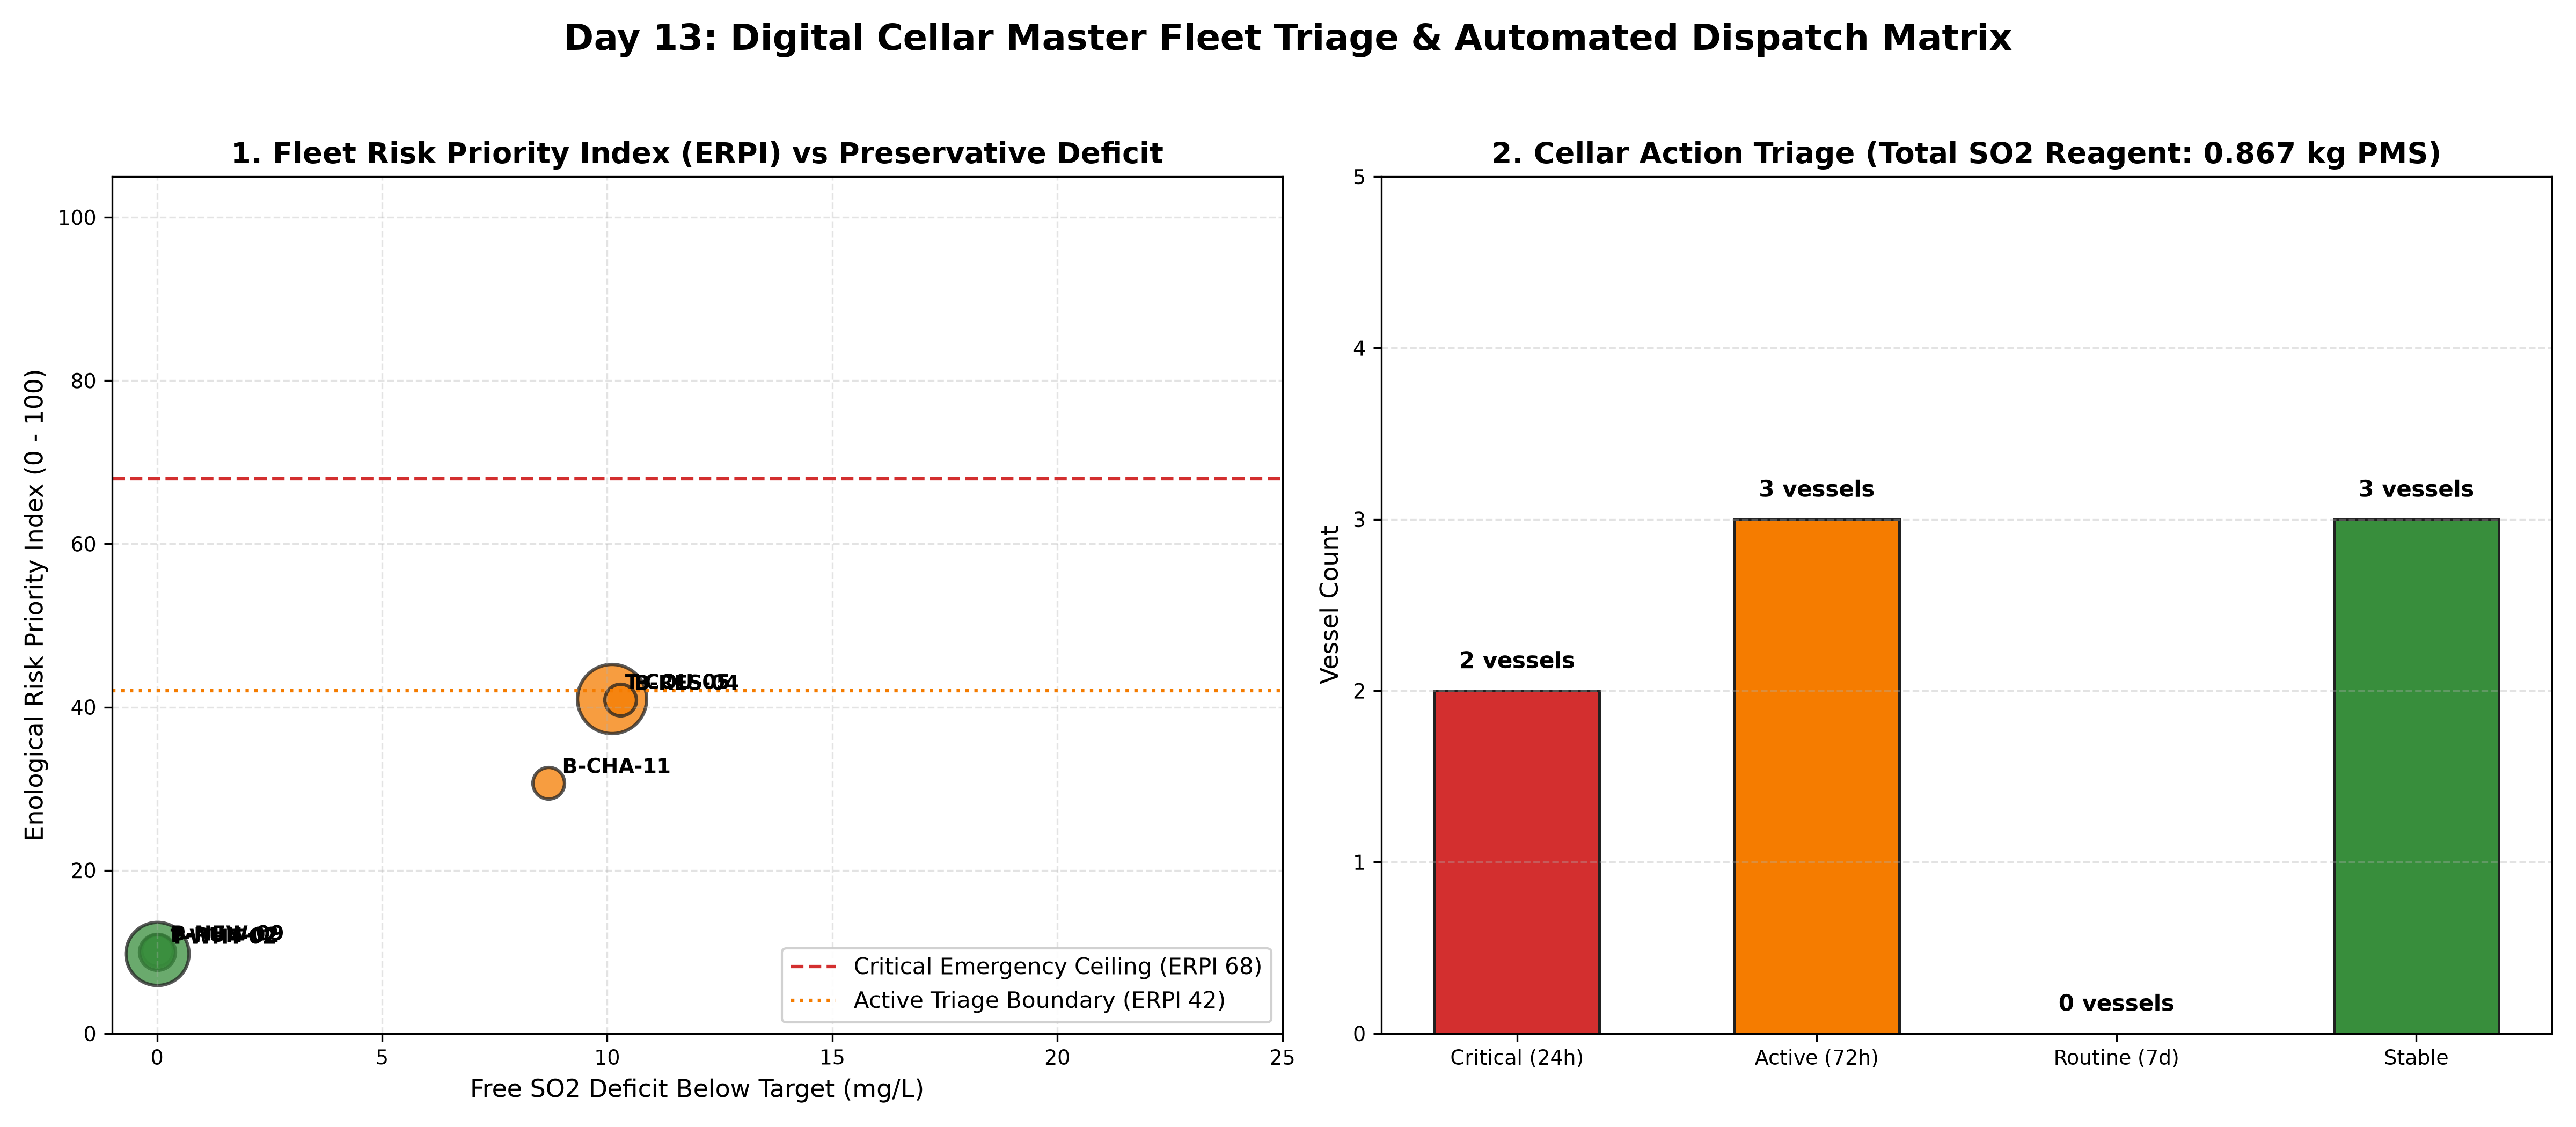

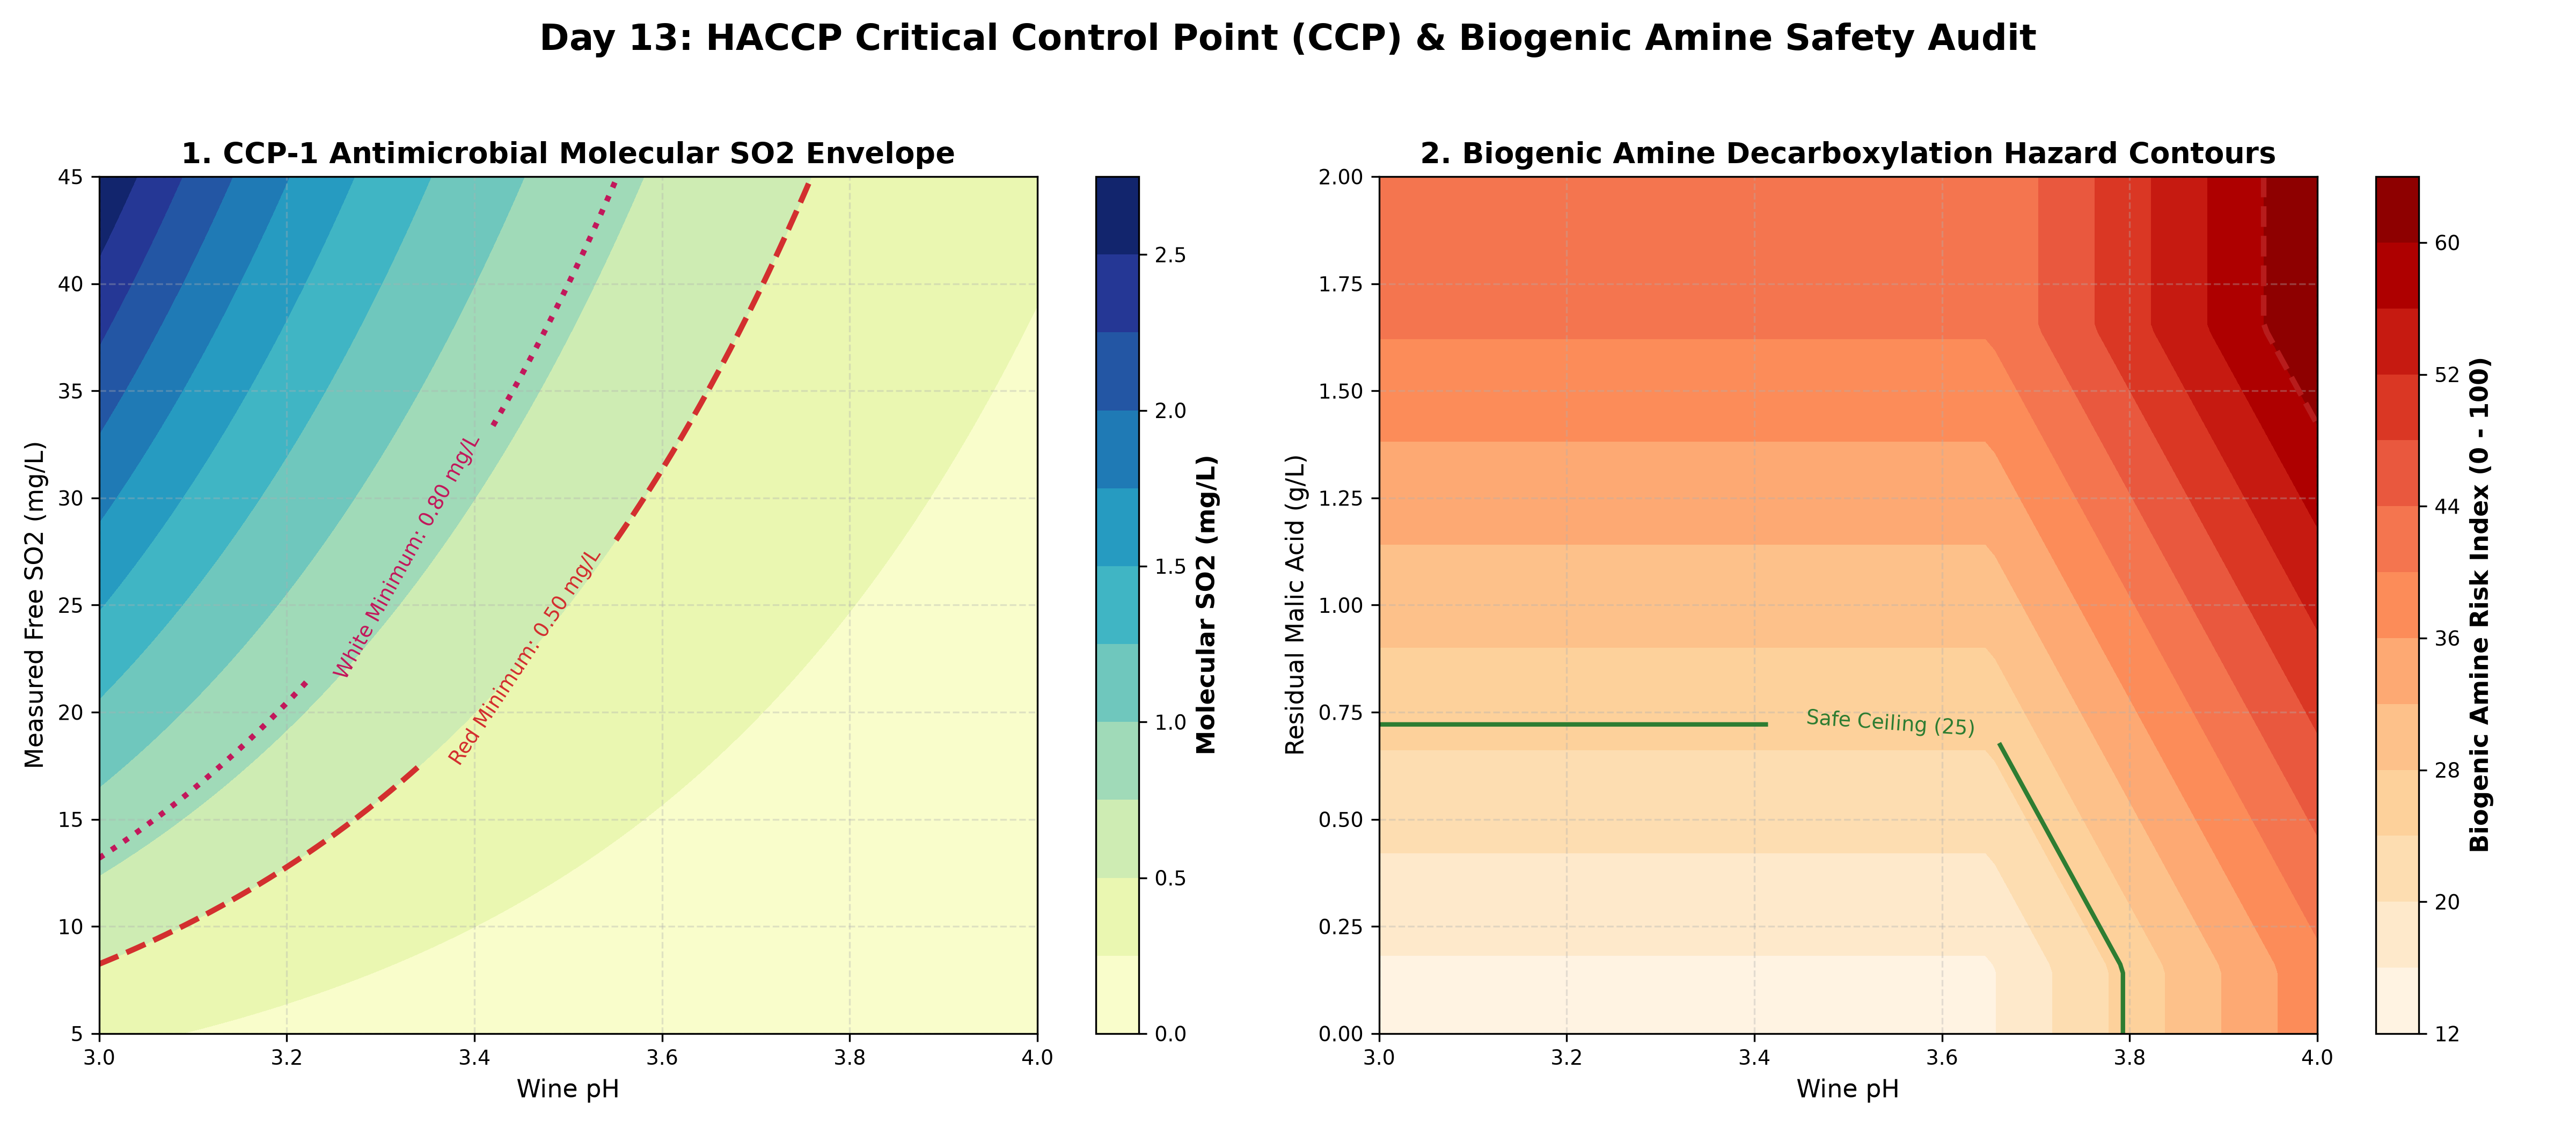

In [7]:
from IPython.display import Image, display
display(Image(filename='reports/figures/day13_malolactic_fermentation_kinetics.png'))
display(Image(filename='reports/figures/day13_oak_maturation_wood_extractives.png'))
display(Image(filename='reports/figures/day13_cellar_master_dispatch_matrix.png'))
display(Image(filename='reports/figures/day13_haccp_compliance_and_biogenic_risk.png'))